# 第七轮总览：概率误差改善，70% 尚未达到

四条路线完成 **35 个拟合配置**：TabICLv2/匹配控制 6、得分监督 10、市场软标签 7、本人早轮次 12。
另有 foundation 6 个、margin 10 个固定混合对照，以及 event 预设的有限非负混合网格；混合数不计作新增拟合配置。
所有结果覆盖同一 **2,588 场 2023 比赛**，决策阈值始终为 0.5。70% 至少需要 **1,812 场正确**。
2024–2025 最终测试仍封存；由于 2023 已反复查看，本轮全部结果都是探索，不是 SOTA 或最终测试证明。

最有价值的新候选是使用历史市场软标签训练的 `market_lambda1`：**1,712 / 2,588 = 66.15%，log loss 0.604599**。
它在预测时只需要原 T−21 历史特征；训练额外用到 2021–2022 开盘概率，因此不能把收益归因于纯历史比赛建模。
原 R4 纯历史概率推荐继续作为独立信息条件保留。各分支的门槛和冻结选择照实保留，不能用 2023 重新替换。

## 原 T−21 历史条件与既有基准

| 比较及角色 | 正确数 / 2,588 | Accuracy | Log loss ↓ | 距 70% 额外正确数 |
| --- | ---: | ---: | ---: | ---: |
| 排名 logistic 原基准 | 1,640 | 63.37% | 0.629796 | 172 |
| R4：保留的纯历史概率推荐 | 1,696 | 65.53% | 0.609407 | 116 |
| R5：冻结准确率探索组合 | 1,715 | 66.27% | 0.609871 | 97 |
| R5：此前最低观察 loss 对照 | 1,706 | 65.92% | 0.606453 | 106 |
| 整体 Elo 原基准（开发期选 K=32） | 1,640 | 63.37% | 0.639146 | 172 |
| TabICLv2：分支冻结选择 | 1,686 | 65.15% | 0.614779 | 126 |
| 得分监督：pooled 冻结探索，门槛失败 | 1,693 | 65.42% | 0.607165 | 119 |

原整体 Elo 为开发期选出的 `raw_elo_k32_diff`，来自最初同队列正式基准，使用相同 T−21 截止；其概率未经新一轮事后校准。
排名一行是原排名 logistic 概率基准，分类与原排名规则一致。
TabICLv2 的分支冻结选择是 0.75 基础模型 / 0.25 R4 概率混合；虽通过 2022 门槛，2023 却比 R4 少对 10 场、loss 更高。
保留这一失败，不把较好的另一混合追认为当时选择。基础模型只在合成表格上预训练；论文中的一般表格优势并不保证网球时间外推收益。
得分监督的 pooled 探索选择为 0.5 点数监督 / 0.5 R4；其门槛未通过。该分支未选中的 points_C0.1 为 1,714 场正确，仍未超过旧 R5 的 1,715。

## 推断仍为 T−21，但训练含历史市场监督

| 比较及角色 | 正确数 / 2,588 | Accuracy | Log loss ↓ | 距 70% 额外正确数 |
| --- | ---: | ---: | ---: | ---: |
| 均匀平滑：未选中的最高准确率观察 | 1,716 | 66.31% | 0.622271 | 96 |
| 市场软标签：分支冻结选择 | 1,712 | 66.15% | 0.604599 | 100 |

全部 33,833 条训练目标保留，其中 **4,854** 条可用 2021–2022 历史开盘概率。
没有加载 2023 市场报价；部署时也不需要价格。缺失教师概率的训练行保留硬标签，均匀平滑控制修改完全相同的行。
与相同结构、相同数据的 hard-label 控制（也是旧 R5 最低观察 loss 模型）相比，冻结学生多对 6 场，
loss 降低 **0.001855**，条件日期块区间 **[-0.000299, +0.003986]** 跨过零。
这是有希望的概率结果，尚不足以确认泛化提升。原始市场价格本身的 2023 探索比较结果属于更晚信息条件，不纳入这里的排行。

未选中的 `uniform_lambda1` 确实以 **1,716 场正确**比旧历史模型最高观察多对 1 场，不能说所有新配置都未刷新准确率；
但它的 loss **0.622271** 明显更差，而且未通过开发期选择，不能当作推荐升级。
它距 70% 仍差 **96 场**；冻结市场学生差 **100 场**。本轮预先冻结的新分支选择均未超过旧 R5 的 66.27% 准确率。

## 加入本届本人早轮次：更晚的信息条件

| 比较及角色 | 正确数 / 2,588 | Accuracy | Log loss ↓ | 距 70% 额外正确数 |
| --- | ---: | ---: | ---: | ---: |
| 本人早轮次：pooled 冻结探索，门槛失败 | 1,693 | 65.42% | 0.607325 | 119 |

仅使用本人严格更早的淘汰赛轮次，**1,445** 场有合格早轮历史，其余 **1,143** 场严格回退到 R4。
2022 门槛只多对 7 场，未升级；pooled 冻结组合在 2023 为 1,693 场正确。
本分支最高新观察是两个 load 模型的 1,702 场正确，也未超过旧 R5。完整 12 配置及 40 行匹配信息对照见[赛事进程报告](results/round7/event/report_summary.md)。
轮次信息可能较晚获得，不能把它与原 T−21 条件的模型收益相加解释。

## 冻结规则与门槛

先在早期开发折按 accuracy 选择，要求 log loss 不比 R4 高超过 0.005；再看 2022 至少 +0.5 个百分点的 accuracy 门槛及相同 loss 护栏。
pooled 开发折选择在各分支 2023 评分之前保存。市场监督由于可用报价年份限制，以 2021 下半年为早期选择折；其 pooled 队列与其他分支不同，不直接横比 CV 值。

| 分支 | 早期选择期 | 2022 净增正确 | Accuracy 变化 / pp | Log loss 变化 ↓ | 记录的分支决策 |
| --- | --- | ---: | ---: | ---: | --- |
| TabICLv2 | 2020–2021 | +26 / 2,528 | +1.028 | -0.000134 | `adopt_foundation` |
| 得分监督 | 2020–2021 | +3 / 2,528 | +0.119 | -0.001415 | `retain_round4` |
| 市场软标签 | 2021 下半年 | +17 / 2,528 | +0.672 | -0.003950 | `adopt_distillation` |
| 本人早轮次 | 2020–2021 | +7 / 2,528 | +0.277 | -0.002708 | `retain_round4` |

R4 本身和 2022 门槛已在此前轮次使用，因此该门槛是探索流程约束，不是独立验证或显著性检验。
日期块区间也没有覆盖完整搜索不确定性和跨日期球员依赖。没有把某一分支门槛通过解释为全局新冠军。
下一位评估者应在打开最终测试前固定比较清单，保留 R4、既有 R5 对照及各分支冻结候选的不同角色。



## 复跑与交付

先按[建模指南](docs/modeling.md)复现之前各轮，包括第三轮目标、第五轮模型和第六轮迁移特征矩阵。常规三分支与报告使用原 `.venv`：

```bash
.venv/bin/python -m scripts.train_margin_round7
.venv/bin/python -m scripts.train_distillation_round7
.venv/bin/python -m scripts.train_event_round7
```

基础模型使用隔离环境，禁止升级原建模环境。固定依赖快照见[requirements-foundation.txt](requirements-foundation.txt)，在 Apple M4 Pro / MPS、Python 3.12 实测：

```bash
python3.12 -m venv .venv-foundation
.venv-foundation/bin/python -m pip install -r requirements-foundation.txt
.venv-foundation/bin/python -m scripts.setup_foundation_round7
.venv-foundation/bin/python -m scripts.train_foundation_round7
.venv/bin/python -m scripts.report_round7
```

下载器仅获取官方公共 `jingang/TabICL` 的固定 revision `4dcd344ece2c00be9e831fdd35bed57b5ad83e19`，
核对 110,368,038 字节 checkpoint 的 SHA-256 `bdc7dbd5e4ff21f8f0456fcf90c6b7cdf72dbea960f2d05b19bec19f9b3d4ed0`。
完整配置固定为 64 列、原始上下文 2,048/4,096 行（交换后 4,096/8,192）、4 个 ensemble 成员、fp32；CPU/MPS 内存调度变更已单列记录。
该分支本地上下文模型约 2.5 GB，权重及大中间文件不提交 Git，按固定源重建；CPU 或其他硬件未据此证明有相同速度或逐位结果。
报告器只读取冻结产物，复算各行指标、核验目标 ID/标签一致性，然后生成 CSV、图、已执行 notebook 和 HTML；不会重训或重新挑选模型。

[完整比较 CSV](results/round7/overview_comparison.csv) · [已执行 notebook](round7.ipynb) · [HTML](round7.html) ·
[本轮协议](docs/research/round7_protocol.md) · [基础模型报告](results/round7/foundation/report_summary.md) ·
[得分监督报告](results/round7/margin/report_summary.md) · [市场学生报告](results/round7/distillation/report_summary.md) · [赛事进程报告](results/round7/event/report_summary.md)。
四分支的重载、对称性、时间选择与来源检查见各自的独立审计：
[foundation](results/round7/foundation/artifact_audit.json)、[margin](results/round7/margin/artifact_audit.json)、[distillation](results/round7/distillation/artifact_audit.json)、[event](results/round7/event/artifact_audit.json)。


,branch,model,role,correct,accuracy,mean_log_loss
0,baseline,rank_reference,排名 logistic 原基准,1640,0.633694,0.629796
1,baseline,previous_probability_recommendation,R4：保留的纯历史概率推荐,1696,0.655332,0.609407
2,baseline,previous_round5_exploration,R5：冻结准确率探索组合,1715,0.662674,0.609871
3,baseline,previous_round5_best_loss,R5：此前最低观察 loss 对照,1706,0.659196,0.606453
4,baseline,raw_elo_k32_diff,整体 Elo 原基准（开发期选 K=32）,1640,0.633694,0.639146
15,foundation,tabicl_context4096_r4blend0.75,TabICLv2：分支冻结选择,1686,0.651468,0.614779
38,margin,margin_points_C0.01_r4blend0.5,得分监督：pooled 冻结探索，门槛失败,1693,0.654173,0.607165
42,distillation,uniform_lambda1,均匀平滑：未选中的最高准确率观察,1716,0.663060,0.622271
45,distillation,market_lambda1,市场软标签：分支冻结选择,1712,0.661515,0.604599
62,event,accuracy_grid_blend,本人早轮次：pooled 冻结探索，门槛失败,1693,0.654173,0.607325


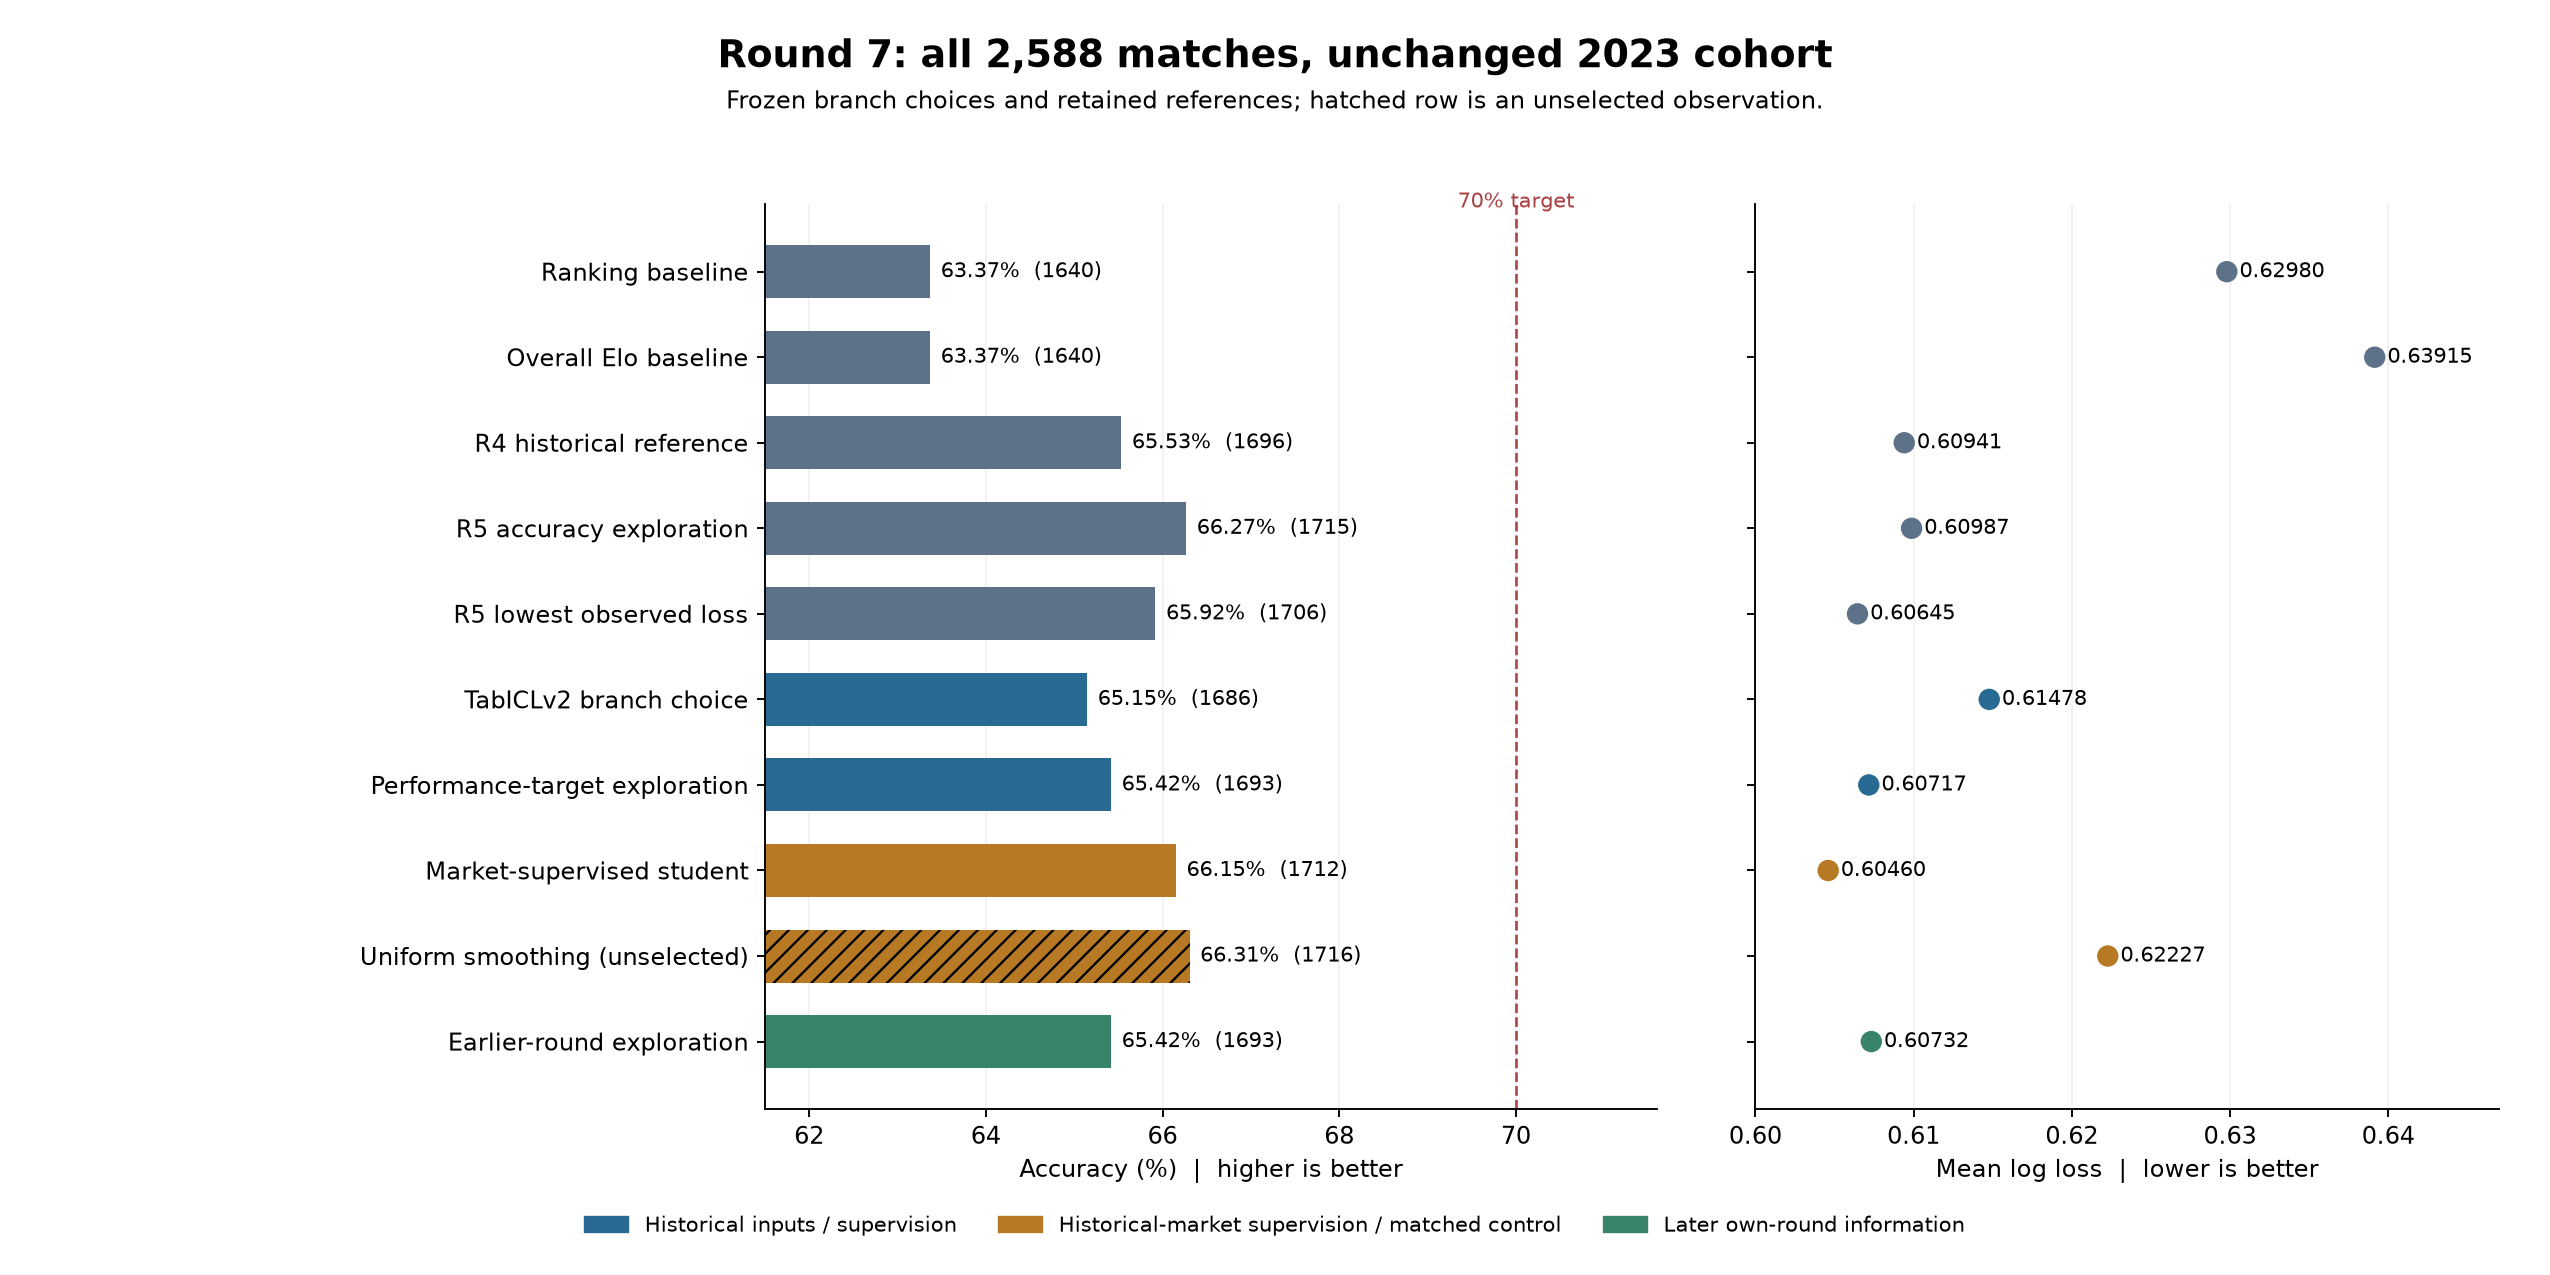

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image
root = Path.cwd()
out = root / 'results/round7'
comparison = pd.read_csv(out / 'overview_comparison.csv')
assert comparison.matches.eq(2588).all()
display(comparison.loc[comparison.display, ['branch','model','role','correct','accuracy','mean_log_loss']])
display(Image(filename=str(out / 'round7_comparison.png')))

## 全部已保存结果

此表保留未选中的控制和各分支重复的旧参考；不按 2023 重新选模型。

In [2]:
with pd.option_context('display.max_rows', 100, 'display.max_colwidth', 70):
    display(comparison[['branch','model','role','correct','accuracy','mean_log_loss']])

,branch,model,role,correct,accuracy,mean_log_loss
0,baseline,rank_reference,排名 logistic 原基准,1640,0.633694,0.629796
1,baseline,previous_probability_recommendation,R4：保留的纯历史概率推荐,1696,0.655332,0.609407
2,baseline,previous_round5_exploration,R5：冻结准确率探索组合,1715,0.662674,0.609871
3,baseline,previous_round5_best_loss,R5：此前最低观察 loss 对照,1706,0.659196,0.606453
4,baseline,raw_elo_k32_diff,整体 Elo 原基准（开发期选 K=32）,1640,0.633694,0.639146
5,foundation,round5_pooled_comparator,既有对照,1715,0.662674,0.609871
6,foundation,round5_probability_comparator,既有对照,1706,0.659196,0.606453
7,foundation,round4_reference,既有对照,1696,0.655332,0.609407
8,foundation,tabicl_context4096_r4blend0.25,预设但未选中的控制；2023 观察,1696,0.655332,0.609756
9,foundation,tabicl_context4096_r4blend0.5,预设但未选中的控制；2023 观察,1696,0.655332,0.611506


## 冻结选择与门槛

市场学生的早期折为 2021 下半年；其他分支为 2020–2021，不能混用 pooled CV 队列。

In [3]:
choices = []
for branch in ('foundation','margin','distillation','event'):
    frozen = json.loads((out / branch / 'frozen_selection.json').read_text())
    gate = frozen['procedure_gate']
    choices.append(dict(branch=branch, recommendation=frozen['recommendation'], pooled_choice=frozen['pooled_selection']['choice'], procedure=gate['procedure'], gate_accuracy_gain=gate['accuracy_improvement'], gate_loss_change=gate['candidate_2022_loss']-gate['reference_2022_loss']))
display(pd.DataFrame(choices))

,branch,recommendation,pooled_choice,procedure,gate_accuracy_gain,gate_loss_change
0,foundation,tabicl_context4096_r4blend0.75,tabicl_context4096_r4blend0.75,adopt_foundation,0.010285,-0.000134
1,margin,round4_reference,margin_points_C0.01_r4blend0.5,retain_round4,0.001187,-0.001415
2,distillation,market_lambda1,market_lambda1,adopt_distillation,0.006725,-0.003950
3,event,previous_probability_recommendation,accuracy_grid_blend,retain_round4,0.002769,-0.002708


## 本人早轮次匹配信息对照

每行同学习器、同回退策略；CV 与 2023 分开。

In [4]:
matched = pd.read_csv(out / 'event/matched_information_controls.csv')
with pd.option_context('display.max_rows', 50):
    display(matched)

,comparison,learner,baseline,candidate,period,matches,baseline_accuracy,candidate_accuracy,accuracy_gain,baseline_log_loss,candidate_log_loss,log_loss_reduction
0,base_to_context,linear,event_base_linear,event_context_linear,2020,1214,0.660626,0.657331,-0.003295,0.606029,0.606348,-0.000319
1,base_to_context,linear,event_base_linear,event_context_linear,2021,2388,0.657873,0.660804,0.002931,0.608512,0.609105,-0.000593
2,base_to_context,linear,event_base_linear,event_context_linear,2022,2528,0.672073,0.672864,0.000791,0.592240,0.592551,-0.000311
3,base_to_context,linear,event_base_linear,event_context_linear,pooled_2020_2022,6130,0.664274,0.665090,0.000816,0.601309,0.601732,-0.000423
4,base_to_context,linear,event_base_linear,event_context_linear,2023_exploratory,2588,0.654946,0.653400,-0.001546,0.608341,0.608370,-0.000029
5,base_to_context,spline,event_base_spline,event_context_spline,2020,1214,0.662273,0.661450,-0.000824,0.606160,0.606496,-0.000337
6,base_to_context,spline,event_base_spline,event_context_spline,2021,2388,0.660804,0.657035,-0.003769,0.608715,0.609251,-0.000537
7,base_to_context,spline,event_base_spline,event_context_spline,2022,2528,0.674446,0.676028,0.001582,0.591857,0.592226,-0.000369
8,base_to_context,spline,event_base_spline,event_context_spline,pooled_2020_2022,6130,0.666721,0.665742,-0.000979,0.601257,0.601684,-0.000428
9,base_to_context,spline,event_base_spline,event_context_spline,2023_exploratory,2588,0.655332,0.653014,-0.002318,0.608863,0.608827,0.000035
